# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [2]:
ROLL_NO = 1024170364         # <-- your full roll number
NAME = "Mehakdeep kaur"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [3]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [4]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [5]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170364   Name: Mehakdeep kaur   Fingerprint: 805D4925   Tickets: 16

Ticket_ID                                                                              Ticket_Text
      T01                  I cannot access the password during the lab. I don't know what changed.
      T02                                     The email crashes while opening. Can you check this?
      T03        I cannot access the Wi-Fi after restarting the system. I don't know what changed.
      T04          I can't open the projector while uploading the file. Is there another solution?
      T05                               I can't open the Python during the lab. Please resolve it.
      T06      I am unable to use the server when I use mobile hotspot. Is there another solution?
      T07                        Student portal failed to open since yesterday. Please resolve it.
      T08     I keep getting logged out of the LMS when I use mobile hotspot. It worked yesterday.
      T09              

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [14]:
# Your code
processed = {}

for _, row in df.iterrows():
    processed[row["Ticket_ID"]] = process_ticket(row["Ticket_Text"])

print("All tickets processed successfully.")


All tickets processed successfully.


In [15]:
rows = []

for _, row in df.iterrows():
    ticket_id = row["Ticket_ID"]
    result = processed[ticket_id]

    rows.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

preprocessing_df = pd.DataFrame(rows)

preprocessing_df

,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,17,2,9,14,6
1,T02,2,11,2,5,11,4
2,T03,2,18,2,9,15,7
3,T04,2,16,2,6,15,8
4,T05,2,14,2,5,12,7
5,T06,2,18,2,8,16,8
6,T07,2,12,2,2,11,8
7,T08,2,18,2,7,16,9
8,T09,2,13,2,6,13,5
9,T10,2,18,2,9,17,7


In [16]:
total = {
    "Ticket_ID": "TOTAL",
    "Sentences": preprocessing_df["Sentences"].sum(),
    "Tokens": preprocessing_df["Tokens"].sum(),
    "Punctuation Tokens": preprocessing_df["Punctuation Tokens"].sum(),
    "Stopwords": preprocessing_df["Stopwords"].sum(),
    "Unique Tokens": preprocessing_df["Unique Tokens"].sum(),
    "Final Tokens": preprocessing_df["Final Tokens"].sum()
}

preprocessing_final = pd.concat(
    [preprocessing_df, pd.DataFrame([total])],
    ignore_index=True
)

display(preprocessing_final)

,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,17,2,9,14,6
1,T02,2,11,2,5,11,4
2,T03,2,18,2,9,15,7
3,T04,2,16,2,6,15,8
4,T05,2,14,2,5,12,7
5,T06,2,18,2,8,16,8
6,T07,2,12,2,2,11,8
7,T08,2,18,2,7,16,9
8,T09,2,13,2,6,13,5
9,T10,2,18,2,9,17,7


In [17]:
ticket_id = "T01"

print("Ticket ID:", ticket_id)
print("Ticket:")
print(df.loc[df["Ticket_ID"] == ticket_id, "Ticket_Text"].iloc[0])

result = processed[ticket_id]

print("\nACTUAL TOKENS:")
print(result["tokens"])

print("\nPUNCTUATION TOKENS:")
print(result["punct"])

print("\nSTOPWORDS:")
print(result["stops"])

print("\nFINAL TOKENS:")
print(result["final"])

Ticket ID: T01
Ticket:
I cannot access the password during the lab. I don't know what changed.

ACTUAL TOKENS:
['i', 'can', 'not', 'access', 'the', 'password', 'during', 'the', 'lab', '.', 'i', 'do', "n't", 'know', 'what', 'changed', '.']

PUNCTUATION TOKENS:
['.', '.']

STOPWORDS:
['i', 'can', 'not', 'the', 'during', 'the', 'i', 'do', 'what']

FINAL TOKENS:
['access', 'password', 'lab', "n't", 'know', 'changed']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [18]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code
import re

In [19]:
# Words longer than 5 letters
long_words_pattern = r"\b[A-Za-z]{6,}\b"

# Numbers, decimals and versions
numbers_pattern = r"\b\d+(?:\.\d+)+\b|\b\d+\b"

# Capitalized words
capitalized_pattern = r"\b[A-Z][a-zA-Z]*\b"

# Words beginning with a vowel
vowel_pattern = r"\b[AEIOUaeiou][A-Za-z]*\b"

# Email addresses
email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"

# URLs
url_pattern = r"(?:https?://|www\.)[^\s]+"

# Phone numbers
phone_pattern = r"(?<!\w)(?:\+?\d[\d\s().-]{7,}\d)(?!\w)"

In [20]:
raw_tickets = df["Ticket_Text"].tolist()

for ticket_id, text in zip(df["Ticket_ID"], raw_tickets):

    print("=" * 70)
    print(ticket_id)
    print(text)

    print("\nLonger than 5 letters:")
    print(re.findall(long_words_pattern, text))

    print("\nNumbers:")
    print(re.findall(numbers_pattern, text))

    print("\nCapitalized words:")
    print(re.findall(capitalized_pattern, text))

    print("\nWords beginning with vowel:")
    print(re.findall(vowel_pattern, text))

T01
I cannot access the password during the lab. I don't know what changed.

Longer than 5 letters:
['cannot', 'access', 'password', 'during', 'changed']

Numbers:
[]

Capitalized words:
['I', 'I']

Words beginning with vowel:
['I', 'access', 'I']
T02
The email crashes while opening. Can you check this?

Longer than 5 letters:
['crashes', 'opening']

Numbers:
[]

Capitalized words:
['The', 'Can']

Words beginning with vowel:
['email', 'opening']
T03
I cannot access the Wi-Fi after restarting the system. I don't know what changed.

Longer than 5 letters:
['cannot', 'access', 'restarting', 'system', 'changed']

Numbers:
[]

Capitalized words:
['I', 'Wi', 'Fi', 'I']

Words beginning with vowel:
['I', 'access', 'after', 'I']
T04
I can't open the projector while uploading the file. Is there another solution?

Longer than 5 letters:
['projector', 'uploading', 'another', 'solution']

Numbers:
[]

Capitalized words:
['I', 'Is']

Words beginning with vowel:
['I', 'open', 'uploading', 'Is', 'ano

In [21]:
for ticket_id, text in zip(df["Ticket_ID"], raw_tickets):

    replaced = re.sub(email_pattern, "<EMAIL>", text)
    replaced = re.sub(url_pattern, "<URL>", replaced)
    replaced = re.sub(phone_pattern, "<PHONE>", replaced)

    if replaced != text:
        print(ticket_id)
        print("Original :", text)
        print("Replaced :", replaced)
        print()

T16
Original : Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.
Replaced : Write to <EMAIL> or visit <URL>



**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [22]:
# Your code
from nltk.tokenize import RegexpTokenizer

custom_pattern = r"""
https?://[^\s]+
|www\.[^\s]+
|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}
|\+?\d[\d\s().-]{7,}\d
|\d+(?:\.\d+)+
|\d+\.\d+
|[A-Za-z]+(?:[-'][A-Za-z]+)+
|[A-Za-z]+
|\d+
"""

tokenizer = RegexpTokenizer(custom_pattern, flags=re.VERBOSE)

def my_tokenize(text):
    return tokenizer.tokenize(text)

In [23]:
for i, line in enumerate(TEST_LINES, 1):

    print("=" * 60)
    print("TEST LINE", i)
    print(line)

    print("\nMy tokenizer:")
    print(my_tokenize(line))

TEST LINE 1
Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.

My tokenizer:
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
TEST LINE 2
Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.

My tokenizer:
['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250']
TEST LINE 3
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.

My tokenizer:
['The', 'state-of-the-art', 'lab', "isn't", 'open', 'log-in', 'at', '5.30', 'p', 'm', "didn't", 'work']


In [24]:
for i, line in enumerate(TEST_LINES, 1):

    custom = my_tokenize(line)
    nltk_tokens = word_tokenize(line)

    print("=" * 70)
    print("TEST LINE", i)
    print(line)

    print("\nmy_tokenize():")
    print(custom)

    print("\nword_tokenize():")
    print(nltk_tokens)

TEST LINE 1
Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.

my_tokenize():
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']

word_tokenize():
['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
TEST LINE 2
Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.

my_tokenize():
['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250']

word_tokenize():
['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
TEST LINE 3
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.

my_tokenize()

In [25]:
custom_tokens = {}

for _, row in df.iterrows():

    ticket_id = row["Ticket_ID"]
    text = row["Ticket_Text"]

    custom_tokens[ticket_id] = my_tokenize(text)

    print(ticket_id, ":", custom_tokens[ticket_id])

T01 : ['I', 'cannot', 'access', 'the', 'password', 'during', 'the', 'lab', 'I', "don't", 'know', 'what', 'changed']
T02 : ['The', 'email', 'crashes', 'while', 'opening', 'Can', 'you', 'check', 'this']
T03 : ['I', 'cannot', 'access', 'the', 'Wi-Fi', 'after', 'restarting', 'the', 'system', 'I', "don't", 'know', 'what', 'changed']
T04 : ['I', "can't", 'open', 'the', 'projector', 'while', 'uploading', 'the', 'file', 'Is', 'there', 'another', 'solution']
T05 : ['I', "can't", 'open', 'the', 'Python', 'during', 'the', 'lab', 'Please', 'resolve', 'it']
T06 : ['I', 'am', 'unable', 'to', 'use', 'the', 'server', 'when', 'I', 'use', 'mobile', 'hotspot', 'Is', 'there', 'another', 'solution']
T07 : ['Student', 'portal', 'failed', 'to', 'open', 'since', 'yesterday', 'Please', 'resolve', 'it']
T08 : ['I', 'keep', 'getting', 'logged', 'out', 'of', 'the', 'LMS', 'when', 'I', 'use', 'mobile', 'hotspot', 'It', 'worked', 'yesterday']
T09 : ['LMS', 'is', 'running', 'slowly', 'during', 'the', 'lab', 'Can', '

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [26]:
# Your code
from nltk.stem import PorterStemmer, LancasterStemmer
from nltk.stem import RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

all_final_tokens = []

for ticket_id in processed:
    all_final_tokens.extend(processed[ticket_id]["final"])

unique_final_tokens = sorted(set(all_final_tokens))

print("Total final tokens:", len(all_final_tokens))
print("Unique final tokens:", len(unique_final_tokens))

Total final tokens: 101
Unique final tokens: 59


In [27]:
porter = PorterStemmer()
lancaster = LancasterStemmer()

regexp_stemmer = RegexpStemmer(
    r"(ing|ed|es|s)$",
    min=4
)

lemmatizer = WordNetLemmatizer()

In [28]:
def get_wordnet_pos(tag):

    if tag.startswith("J"):
        return wordnet.ADJ

    elif tag.startswith("V"):
        return wordnet.VERB

    elif tag.startswith("N"):
        return wordnet.NOUN

    elif tag.startswith("R"):
        return wordnet.ADV

    else:
        return wordnet.NOUN

In [29]:
tagged_words = pos_tag(unique_final_tokens)

lemma_results = {}

for word, tag in tagged_words:

    wn_pos = get_wordnet_pos(tag)

    lemma_results[word] = lemmatizer.lemmatize(
        word,
        pos=wn_pos
    )

In [30]:
comparison = []

for word in unique_final_tokens:

    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regexp_result = regexp_stemmer.stem(word)
    lemma_result = lemma_results[word]

    if len(set([
        porter_result,
        lancaster_result,
        regexp_result,
        lemma_result
    ])) > 1:

        comparison.append({
            "Word": word,
            "Porter": porter_result,
            "Lancaster": lancaster_result,
            "Regexp": regexp_result,
            "POS Lemma": lemma_result
        })

stemming_df = pd.DataFrame(comparison)

display(stemming_df)

,Word,Porter,Lancaster,Regexp,POS Lemma
0,access,access,access,acces,access
1,another,anoth,anoth,another,another
2,anything,anyth,anyth,anyth,anything
3,campus,campu,camp,campu,campus
4,change,chang,chang,change,change
5,changed,chang,chang,chang,change
6,computer,comput,comput,computer,computer
7,file,file,fil,file,file
8,getting,get,get,gett,get
9,lms,lm,lms,lms,lm


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

In [31]:
# Your code
# S1: all tokens
S1 = []

for ticket_id in processed:
    S1.extend(processed[ticket_id]["tokens"])


# S2: tokens without punctuation
S2 = []

for token in S1:
    if not is_punct(token):
        S2.append(token)


# S3: final tokens
S3 = all_final_tokens


# S4: Porter stemmed S3
S4 = [porter.stem(token) for token in S3]


print("S1 total:", len(S1))
print("S2 total:", len(S2))
print("S3 total:", len(S3))
print("S4 total:", len(S4))

S1 total: 219
S2 total: 188
S3 total: 101
S4 total: 101


In [32]:
def calculate_stats(tokens):

    total_tokens = len(tokens)
    unique_tokens = len(set(tokens))

    TTR = unique_tokens / total_tokens

    return total_tokens, unique_tokens, TTR


statistics = []

for name, corpus in [
    ("S1", S1),
    ("S2", S2),
    ("S3", S3),
    ("S4", S4)
]:

    total, unique, ttr = calculate_stats(corpus)

    statistics.append({
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(ttr, 4)
    })


statistics_df = pd.DataFrame(statistics)

display(statistics_df)

,Corpus,Total Tokens,Unique Tokens,TTR
0,S1,219,88,0.4018
1,S2,188,83,0.4415
2,S3,101,59,0.5842
3,S4,101,55,0.5446


In [33]:
from collections import Counter

print("TOP 10 WORDS IN S1")
print("-" * 30)

for word, count in Counter(S1).most_common(10):
    print(f"{word}: {count}")


print("\nTOP 10 WORDS IN S3")
print("-" * 30)

for word, count in Counter(S3).most_common(10):
    print(f"{word}: {count}")

TOP 10 WORDS IN S1
------------------------------
.: 23
the: 17
i: 15
n't: 6
can: 5
?: 5
is: 5
another: 5
it: 5
to: 5

TOP 10 WORDS IN S3
------------------------------
n't: 6
another: 5
open: 4
use: 4
access: 3
lab: 3
ca: 3
solution: 3
mobile: 3
hotspot: 3


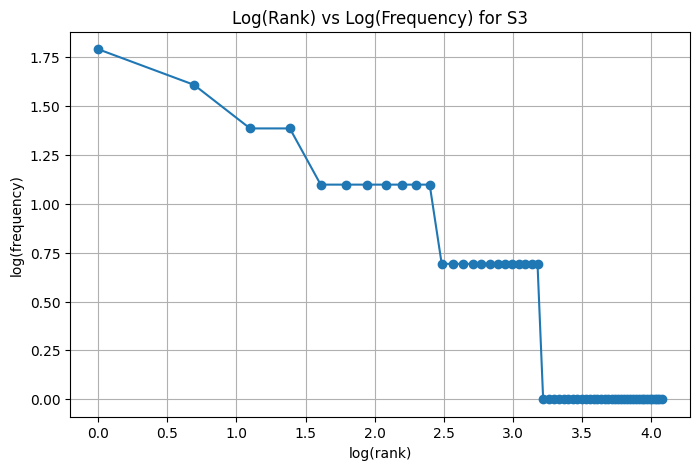

In [34]:
frequencies = sorted(
    Counter(S3).values(),
    reverse=True
)

ranks = np.arange(1, len(frequencies) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    np.log(ranks),
    np.log(frequencies),
    marker="o"
)

plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")

plt.grid(True)
plt.show()

In [35]:
from nltk.util import bigrams

S1_bigrams = list(bigrams(S1))
S3_bigrams = list(bigrams(S3))

print("TOP 5 BIGRAMS — S1")
print("-" * 40)

for bigram, count in Counter(S1_bigrams).most_common(5):
    print(bigram, ":", count)


print("\nTOP 5 BIGRAMS — S3")
print("-" * 40)

for bigram, count in Counter(S3_bigrams).most_common(5):
    print(bigram, ":", count)

TOP 5 BIGRAMS — S1
----------------------------------------
('.', 'i') : 7
('i', 'can') : 3
('can', 'not') : 3
('not', 'access') : 3
('access', 'the') : 3

TOP 5 BIGRAMS — S3
----------------------------------------
('ca', "n't") : 3
('another', 'solution') : 3
('use', 'mobile') : 3
('mobile', 'hotspot') : 3
("n't", 'know') : 2


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*

interception

## 6. Interpretation

### (a) Why does TTR change from S1 to S4?

TTR changes from S1 to S4 because preprocessing removes punctuation and stopwords, while Porter stemming reduces different word forms to common stems. This decreases the number of unique tokens relative to the total number of tokens and therefore changes the TTR.

### (b) Give one example where word_tokenize() and your tokenizer differ.

For example, for the contraction "isn't", my custom tokenizer keeps "isn't" as one token, whereas word_tokenize() may split it into "is" and "n't". This happens because my tokenizer was specifically designed to preserve contractions.

### (c) Give one example where stemming produces an undesirable result.

An undesirable stemming result occurs when a stemmer removes too many characters and produces a form that is not a valid English word. This shows that stemming uses word-form rules and does not always preserve the actual meaning of a word.

### (d) Give one example where POS-aware lemmatization preserves meaning better than stemming.

POS-aware lemmatization considers the grammatical role of a word before finding its base form. Therefore, it can produce a meaningful dictionary form, whereas stemming may simply cut off characters and produce an incomplete stem.
1. Roll Number + Name
        ↓
2. Dataset Generator
        ↓
3. Preprocessing Pipeline
        ↓
4. Dataset Output
   Fingerprint: 805D4925
   Tickets: 16
        ↓
5. PART 1 — Preprocessing
        ↓
6. PART 2 — Regex Extraction
        ↓
7. PART 3 — Custom Tokenization
        ↓
8. PART 4 — Stemming & Lemmatization
        ↓
9. PART 5 — Corpus Statistics
        ↓
10. PART 6 — Interpretation